# PathSnap · Team 111 — Final evaluation on the evaluator test set
**The 10 evaluator trips, run through our frozen final pipeline** — the same code and saved models that the
FastAPI backend uses (`src/pathsnap/pipeline.py`).

**Rules followed (and checked in this notebook):**
1. **No training, tuning or model selection** on these trips: models are loaded from disk; their checksums and
   timestamps are recorded before and after the run.
2. **Reference routes are not used for prediction:** while predicting, any attempt to open a `.route` file raises
   an error (guard below). Reference routes are read **only afterwards**, to score the predictions.

| Step | What |
|---|---|
| 1 | Frozen model artifacts (checksums, timestamps, configuration) |
| 2 | Evaluator data: inventory and quality checks |
| 3 | Prediction with a guard that blocks the reference route |
| 4 | Scoring against the reference routes |
| 5 | Results per trip and overall; classifier-only vs classifier + HMM |
| 6 | Plots and maps |
| 7 | Integrity check after the run |

## Step 0 — Setup

In [1]:
import os, sys, time, json, hashlib, datetime, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
sys.path.insert(0, os.path.join(ROOT, "src"))
import pathsnap.pipeline as pipeline_module
from pathsnap.pipeline import PathSnapPredictor
from pathsnap.data import list_trips, trip_files

EVAL = os.path.join(ROOT, "data", "raw", "evaluator_test")
MODELS = os.path.join(ROOT, "models")
RES = os.path.join(ROOT, "results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(ROOT, "figures"); os.makedirs(FIG, exist_ok=True)
TRIPS = list_trips(EVAL)
print("run at:", datetime.datetime.now().astimezone().strftime("%Y-%m-%d %H:%M:%S UTC%z"))
print("evaluator trips:", TRIPS)

run at: 2026-11-18 10:05:09 UTC+0000
evaluator trips: ['00000015', '00000017', '00000023', '00000030', '00000049', '00000059', '00000067', '00000073', '00000087', '00000094']


## Step 1 — Frozen model artifacts
SHA-256 checksums and last-modified times of every model file. The same checksums are verified again at the end.

In [2]:
def artifact_table():
    rows = []
    for f in sorted(os.listdir(MODELS)):
        p = os.path.join(MODELS, f)
        if os.path.isfile(p) and f.endswith((".joblib", ".json")):
            rows.append(dict(file=f, size_kb=round(os.path.getsize(p) / 1024, 1),
                             last_modified=datetime.datetime.fromtimestamp(os.path.getmtime(p)).astimezone().strftime("%Y-%m-%d %H:%M:%S UTC%z"),
                             sha256=hashlib.sha256(open(p, "rb").read()).hexdigest()[:16]))
    return pd.DataFrame(rows)


before = artifact_table()
data_received = min(os.path.getmtime(os.path.join(EVAL, t)) for t in TRIPS)
print("evaluator data placed in the project at:",
      datetime.datetime.fromtimestamp(data_received).astimezone().strftime("%Y-%m-%d %H:%M:%S UTC%z"))
before

evaluator data placed in the project at: 2026-11-18 10:03:36 UTC+0000


,file,size_kb,last_modified,sha256
0,final_model.joblib,5499.8,2026-11-18 04:28:00 UTC+0000,df8d53da1bd76d3b
1,hmm_config.json,1.0,2026-11-18 04:37:53 UTC+0000,dd11b2cd826e6fa8
2,model_config.json,0.8,2026-11-18 04:28:00 UTC+0000,0a69a3ce266c2b10
3,transition_model.joblib,1.6,2026-11-18 04:35:22 UTC+0000,3ffec4220ed28b8f


In [3]:
predictor = PathSnapPredictor(MODELS)
print("classifier:", predictor.cfg["model"], json.dumps(predictor.cfg["params"]))
print("features:", len(predictor.cfg["features"]), "| candidates:", predictor.cfg["candidates"])
print("decoder:", predictor.hmm_cfg["selected_mode"], predictor.hmm_cfg["modes"][predictor.hmm_cfg["selected_mode"]])

classifier: HistGradientBoostingClassifier {"learning_rate": 0.012860098349830868, "max_leaf_nodes": 97, "min_samples_leaf": 187, "l2_regularization": 1.5953215934534963, "max_iter": 508, "max_features": 0.9945729107982461}
features: 22 | candidates: {'radius': 50.0, 'k_max': 8, 'k_fallback': 3, 'ctx': 3}
decoder: hybrid {'beta': 3.0, 'w_learn': 1.0, 'w_emit': 1.0}


## Step 2 — Evaluator data: inventory and quality checks

In [4]:
inv = []
for tid in TRIPS:
    f = trip_files(os.path.join(EVAL, tid))
    tr = pd.read_csv(f["track"], sep=r"\s+", header=None, names=["lon", "lat", "t"])
    nodes = pd.read_csv(f["nodes"], sep=r"\s+", header=None)
    arcs = pd.read_csv(f["arcs"], sep=r"\s+", header=None)
    dt = np.diff(tr.t.values)
    inv.append(dict(trip=tid, gps_points=len(tr), nodes=len(nodes), arcs=len(arcs),
                    duration_min=round((tr.t.iloc[-1] - tr.t.iloc[0]) / 60, 1),
                    lat=round(tr.lat.mean(), 3), lon=round(tr.lon.mean(), 3),
                    missing=int(tr.isna().sum().sum()), invalid_coords=int(((tr.lon.abs() > 180) | (tr.lat.abs() > 90)).sum()),
                    non_increasing_t=int((dt <= 0).sum()), pct_1s_steps=round(100 * (dt == 1).mean(), 1), max_gap_s=dt.max()))
inv = pd.DataFrame(inv)
print(f"{len(inv)} trips, {inv.gps_points.sum():,} GPS points; missing {inv.missing.sum()}, invalid {inv.invalid_coords.sum()}, "
      f"non-increasing timestamps {inv.non_increasing_t.sum()}")
inv

10 trips, 19,674 GPS points; missing 0, invalid 0, non-increasing timestamps 0


,trip,gps_points,nodes,arcs,duration_min,lat,lon,missing,invalid_coords,non_increasing_t,pct_1s_steps,max_gap_s
0,00000015,6854,1571,3225,114.2,50.820,4.743,0,0,0,100.0,1.000
1,00000017,1346,36724,76425,23.3,48.848,9.053,0,0,0,97.8,8.000
2,00000023,458,5053,10596,7.6,49.765,43.738,0,0,0,100.0,1.000
3,00000030,654,13223,24218,11.1,43.394,-3.775,0,0,0,99.8,14.000
4,00000049,2642,23165,47542,44.0,52.733,39.391,0,0,0,100.0,2.000
5,00000059,1031,12631,24024,17.6,45.566,8.073,0,0,0,98.0,4.000
6,00000067,916,2265,4485,15.7,58.567,31.287,0,0,0,99.3,19.000
7,00000073,1144,12151,25631,28.9,36.237,138.463,0,0,0,93.4,220.001
8,00000087,1399,55234,107451,23.4,43.384,3.495,0,0,0,99.7,2.000
9,00000094,3230,6815,14931,53.9,58.004,38.771,0,0,0,99.9,4.000


## Step 3 — Prediction (reference route blocked)
The guard wraps `numpy.loadtxt` and the pipeline's route loader: if anything tries to read a `.route` file
during prediction, the run stops with an error. Each trip goes through exactly what the API runs:
load + clean → candidates → 22 features → tuned HistGB → hybrid HMM (Viterbi + forward–backward) → stitched route.

In [5]:
class RouteGuard:
    def __enter__(self):
        self._loadtxt, self._load_route = np.loadtxt, pipeline_module.load_route
        def guarded_loadtxt(fname, *a, **k):
            if str(fname).endswith(".route"):
                raise PermissionError(f"blocked: prediction tried to read {fname}")
            return self._loadtxt(fname, *a, **k)
        def blocked(*a, **k):
            raise PermissionError("blocked: prediction tried to load a reference route")
        np.loadtxt = guarded_loadtxt; pipeline_module.load_route = blocked
        return self

    def __exit__(self, *exc):
        np.loadtxt, pipeline_module.load_route = self._loadtxt, self._load_route
        return False


preds = {}
with RouteGuard():
    for tid in TRIPS:
        t0 = time.time()
        preds[tid] = predictor.predict(os.path.join(EVAL, tid))
        preds[tid]["seconds"] = time.time() - t0
        r = preds[tid]["response"]
        print(f"{tid}: {r['n_points']:>5} points -> {len(r['route_arcs']):>4} route arcs, "
              f"mean confidence {r['mean_confidence']:.3f}, {preds[tid]['seconds']:.1f} s")
print("\nall predictions made with the reference routes blocked.")

00000015:  6854 points ->  165 route arcs, mean confidence 0.990, 3.4 s
00000017:  1346 points ->  884 route arcs, mean confidence 0.973, 1.8 s
00000023:   458 points ->   88 route arcs, mean confidence 0.992, 0.3 s
00000030:   654 points ->  365 route arcs, mean confidence 0.977, 0.8 s
00000049:  2642 points ->  505 route arcs, mean confidence 0.999, 1.5 s
00000059:  1031 points ->  510 route arcs, mean confidence 0.979, 1.0 s
00000067:   916 points ->   81 route arcs, mean confidence 0.990, 0.5 s
00000073:  1144 points ->  242 route arcs, mean confidence 0.992, 0.9 s
00000087:  1399 points ->  455 route arcs, mean confidence 0.993, 2.0 s
00000094:  3230 points ->  690 route arcs, mean confidence 0.982, 1.9 s

all predictions made with the reference routes blocked.


## Step 4 — Scoring against the reference routes (only now are `.route` files read)
* **Point accuracy:** share of GPS points whose predicted arc equals the reference arc (reference arc per point from
  the monotonic route alignment, as in training).
* **Classifier-only accuracy:** same, taking the classifier's best candidate per point without the HMM.
* **Route continuity:** share of consecutive points whose arcs are equal or directly connected.
* **Route precision / recall / F1:** length-weighted overlap of the stitched predicted route and the reference route.

In [6]:
rows = []
for tid in TRIPS:
    m = PathSnapPredictor.evaluate(os.path.join(EVAL, tid), preds[tid])
    r = preds[tid]["response"]
    rows.append(dict(trip=tid, gps_points=r["n_points"],
                     point_acc_hmm=m["point_accuracy"], point_acc_classifier_only=m["classifier_only_point_accuracy"],
                     continuity_hmm=m["route_continuity"], continuity_classifier_only=m["classifier_only_route_continuity"],
                     route_precision=m["route_precision"], route_recall=m["route_recall"], route_f1=m["route_f1"],
                     mean_confidence=r["mean_confidence"], gaps_filled=r["gaps_filled"],
                     unbridgeable_breaks=r["unbridgeable_breaks"], reference_label_median_dist_m=m["reference_label_median_dist_m"],
                     inference_s=preds[tid]["seconds"]))
res = pd.DataFrame(rows)
res.to_csv(os.path.join(RES, "evaluator_test_results.csv"), index=False)
res.round(4)

,trip,gps_points,point_acc_hmm,point_acc_classifier_only,continuity_hmm,continuity_classifier_only,route_precision,route_recall,route_f1,mean_confidence,gaps_filled,unbridgeable_breaks,reference_label_median_dist_m,inference_s
0,00000015,6854,0.9573,0.8208,0.9981,0.9419,0.9162,0.9911,0.9522,0.9897,13,0,5.6502,3.3713
1,00000017,1346,0.9443,0.9250,0.8758,0.8387,0.9663,0.9930,0.9795,0.9728,167,0,4.6645,1.8343
2,00000023,458,0.9541,0.9432,0.9781,0.9716,0.9740,0.9892,0.9816,0.9917,10,0,5.7233,0.3305
3,00000030,654,0.8930,0.8089,0.9081,0.8193,0.9670,0.9895,0.9781,0.9766,60,0,4.8826,0.7667
4,00000049,2642,0.9928,0.9894,0.9924,0.9822,0.9628,0.9988,0.9805,0.9991,20,0,4.9303,1.5455
5,00000059,1031,0.9767,0.9612,0.9272,0.8961,0.9851,1.0000,0.9925,0.9790,75,0,4.4356,1.0334
6,00000067,916,0.9814,0.9716,0.9913,0.9770,1.0000,0.9949,0.9974,0.9897,8,0,4.1504,0.5297
7,00000073,1144,0.9869,0.9843,0.9913,0.9790,0.9966,1.0000,0.9983,0.9919,10,0,4.4806,0.9500
8,00000087,1399,0.9979,0.9442,0.9886,0.9285,0.9998,0.9954,0.9976,0.9925,16,0,4.7651,1.9651
9,00000094,3230,0.9675,0.9378,0.9820,0.9452,0.9298,1.0000,0.9636,0.9822,58,0,4.0567,1.9445


## Step 5 — Overall results

In [7]:
n = res.gps_points
overall = pd.Series({
    "trips": len(res), "GPS points": int(n.sum()),
    "point accuracy, classifier + HMM (all points)": (res.point_acc_hmm * n).sum() / n.sum(),
    "point accuracy, classifier only (all points)": (res.point_acc_classifier_only * n).sum() / n.sum(),
    "route continuity, classifier + HMM (trip mean)": res.continuity_hmm.mean(),
    "route continuity, classifier only (trip mean)": res.continuity_classifier_only.mean(),
    "route precision (trip mean)": res.route_precision.mean(),
    "route recall (trip mean)": res.route_recall.mean(),
    "route F1 (trip mean)": res.route_f1.mean(),
    "mean HMM confidence": res.mean_confidence.mean(),
    "unbridgeable breaks (total)": int(res.unbridgeable_breaks.sum()),
    "inference time per trip, s (mean)": res.inference_s.mean(),
})
overall.to_frame("evaluator_test").to_csv(os.path.join(RES, "evaluator_test_overall.csv"))
print(f"HMM gain in point accuracy: {100 * (overall.iloc[2] - overall.iloc[3]):+.2f} points | "
      f"trips improved by the HMM: {(res.point_acc_hmm > res.point_acc_classifier_only).sum()} of {len(res)}")
overall.to_frame("evaluator_test").round(4)

HMM gain in point accuracy: +6.25 points | trips improved by the HMM: 10 of 10


,evaluator_test
trips,10.0000
GPS points,19674.0000
"point accuracy, classifier + HMM (all points)",0.9674
"point accuracy, classifier only (all points)",0.9049
"route continuity, classifier + HMM (trip mean)",0.9633
"route continuity, classifier only (trip mean)",0.9279
route precision (trip mean),0.9698
route recall (trip mean),0.9952
route F1 (trip mean),0.9821
mean HMM confidence,0.9865


### Context: development (student_test) vs evaluator results
Same frozen pipeline; student_test numbers come from development (`results/hmm_comparison.csv`).

In [8]:
dev = pd.read_csv(os.path.join(RES, "hmm_comparison.csv"), index_col=0)
pd.DataFrame({
    "student_test (development)": [dev.loc["classifier_only", "point_acc_micro"], dev.loc["hmm_hybrid", "point_acc_micro"],
                                   dev.loc["hmm_hybrid", "continuity"], dev.loc["hmm_hybrid", "route_f1"]],
    "evaluator_test (final)": [overall.iloc[3], overall.iloc[2], overall.iloc[4], overall.iloc[8]],
}, index=["point accuracy, classifier only", "point accuracy, classifier + HMM", "route continuity (HMM)", "route F1"]).round(4)

,student_test (development),evaluator_test (final)
"point accuracy, classifier only",0.8921,0.9049
"point accuracy, classifier + HMM",0.9553,0.9674
route continuity (HMM),0.9771,0.9633
route F1,0.9454,0.9821


## Step 6 — Plots and maps

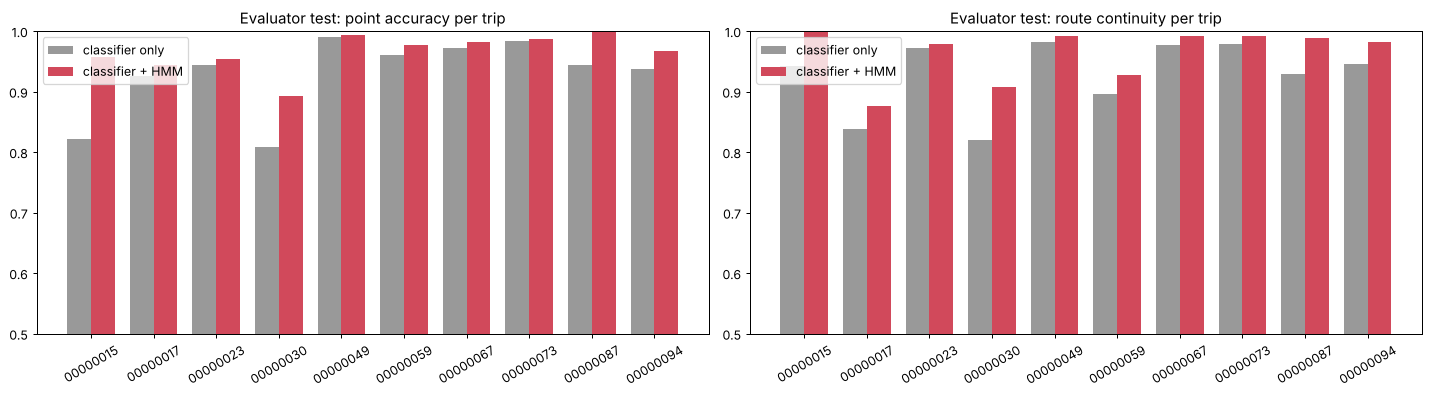

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5)); x = np.arange(len(res)); w = .38
ax[0].bar(x - w / 2, res.point_acc_classifier_only, w, label="classifier only", color="#999999")
ax[0].bar(x + w / 2, res.point_acc_hmm, w, label="classifier + HMM", color="#d1495b")
ax[0].set(xticks=x, xticklabels=res.trip, ylim=(0.5, 1.0), title="Evaluator test: point accuracy per trip"); ax[0].legend()
ax[0].tick_params(axis="x", rotation=30)
ax[1].bar(x - w / 2, res.continuity_classifier_only, w, label="classifier only", color="#999999")
ax[1].bar(x + w / 2, res.continuity_hmm, w, label="classifier + HMM", color="#d1495b")
ax[1].set(xticks=x, xticklabels=res.trip, ylim=(0.5, 1.0), title="Evaluator test: route continuity per trip"); ax[1].legend()
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "evaluator_test_per_trip.png"), dpi=120); plt.show()

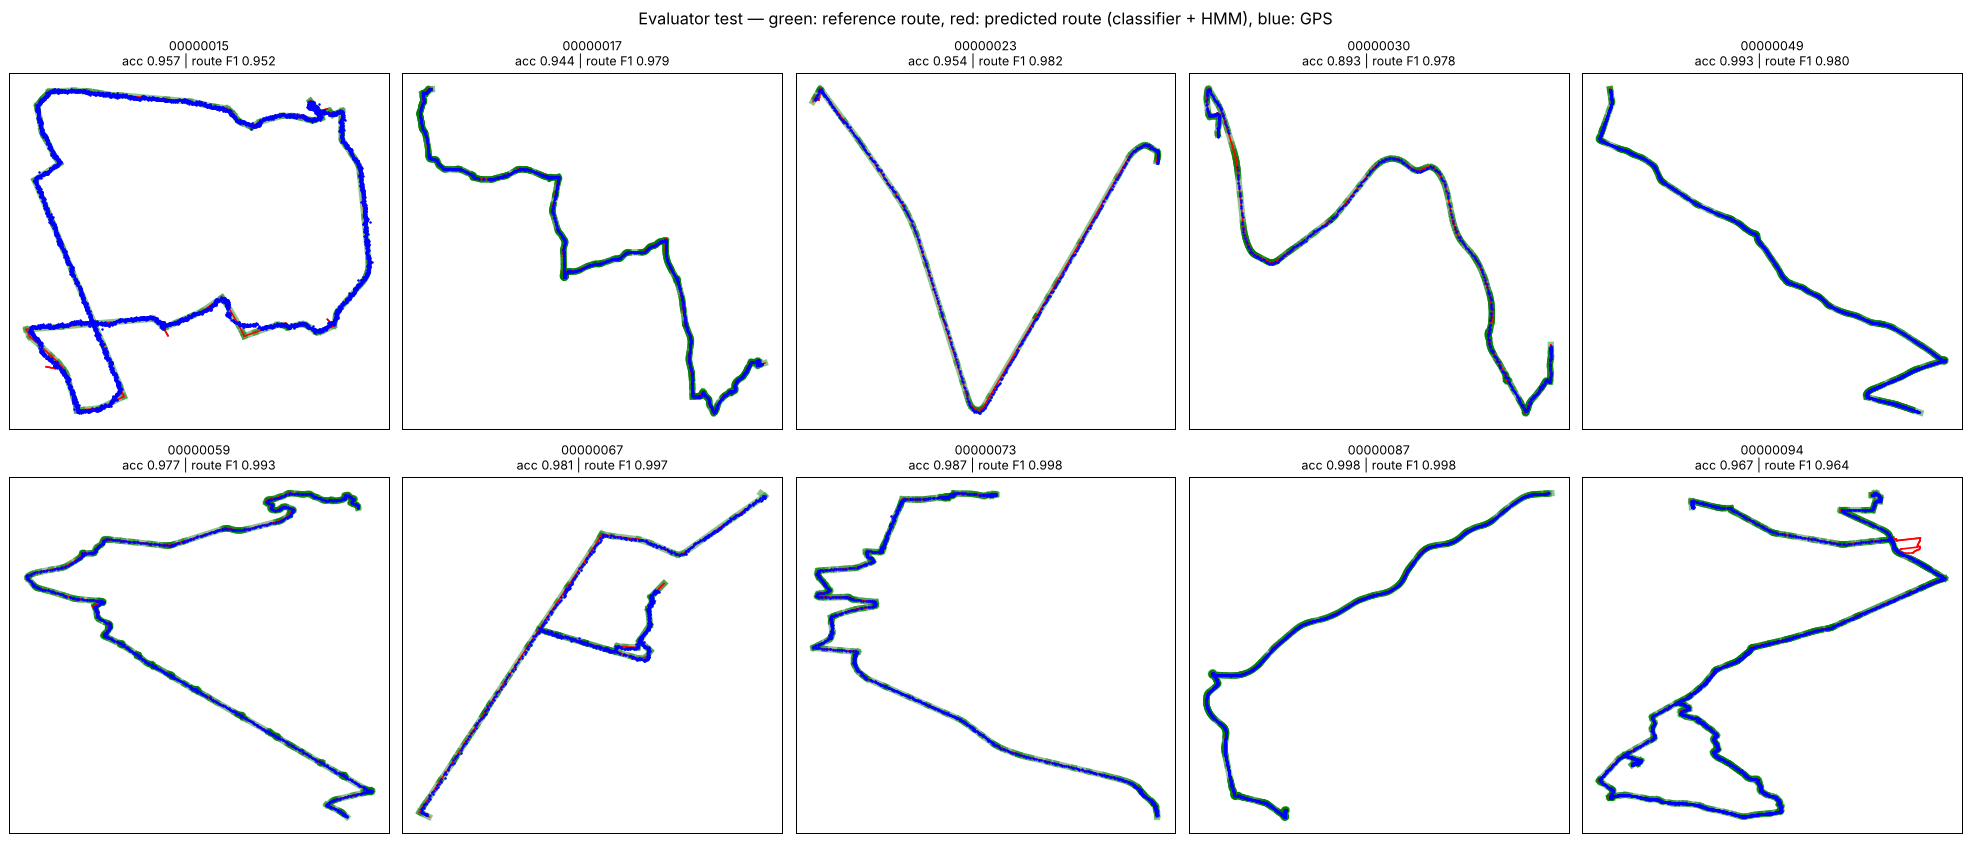

In [10]:
from pathsnap.data import load_route
fig, axs = plt.subplots(2, 5, figsize=(22, 9.5))
for ax, tid in zip(axs.ravel(), TRIPS):
    trip = preds[tid]["trip"]; nl = trip.node_lonlat; ref = load_route(os.path.join(EVAL, tid))
    for e in ref:
        u, v = trip.arcs[e]; ax.plot(nl[[u, v], 0], nl[[u, v], 1], color="green", lw=5, alpha=.45)
    for e in preds[tid]["route"]:
        u, v = trip.arcs[e]; ax.plot(nl[[u, v], 0], nl[[u, v], 1], color="red", lw=1.3)
    ax.scatter(trip.lonlat[:, 0], trip.lonlat[:, 1], s=1, c="blue", zorder=3)
    r = res.set_index("trip").loc[tid]
    ax.set_title(f"{tid}\nacc {r.point_acc_hmm:.3f} | route F1 {r.route_f1:.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Evaluator test — green: reference route, red: predicted route (classifier + HMM), blue: GPS", fontsize=13)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "evaluator_test_maps.png"), dpi=110); plt.show()

### Interactive map (Folium) for the trip with the lowest accuracy
Requires `pip install folium`; saved to `maps/`.

In [11]:
worst = res.sort_values("point_acc_hmm").trip.iloc[0]
try:
    import folium
    trip = preds[worst]["trip"]; nl = trip.node_lonlat; ref = load_route(os.path.join(EVAL, worst))
    conf = np.array(preds[worst]["response"]["confidence"])
    m = folium.Map(location=[trip.lonlat[:, 1].mean(), trip.lonlat[:, 0].mean()], zoom_start=14, tiles=None)
    folium.TileLayer("https://{s}.basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}{r}.png",
                     attr="&copy; OpenStreetMap &copy; CARTO", name="Basemap (English)", subdomains="abcd").add_to(m)
    fg_ref, fg_pred, fg_gps = (folium.FeatureGroup(n) for n in ["Reference route (green)", "Predicted route (red)", "GPS, coloured by confidence"])
    for e in ref:
        u, v = trip.arcs[e]; folium.PolyLine([(nl[u, 1], nl[u, 0]), (nl[v, 1], nl[v, 0])], color="green", weight=7, opacity=.5).add_to(fg_ref)
    folium.PolyLine(preds[worst]["response"]["route_latlon"], color="red", weight=3).add_to(fg_pred)
    for (lon, lat), c in zip(trip.lonlat[::2], conf[::2]):
        folium.CircleMarker([lat, lon], radius=2, weight=0, fill=True, fill_opacity=.9,
                            color="#2a9d8f" if c >= .6 else "#c0392b").add_to(fg_gps)
    for fg in (fg_ref, fg_pred, fg_gps):
        fg.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    os.makedirs(os.path.join(ROOT, "maps"), exist_ok=True)
    out = os.path.join(ROOT, "maps", f"evaluator_{worst}.html"); m.save(out); print("saved", out)
except ImportError:
    print(f"folium not installed -> static maps above; for an interactive map run `pip install folium` (trip {worst})")

folium not installed -> static maps above; for an interactive map run `pip install folium` (trip 00000030)


## Step 7 — Integrity check after the run

In [12]:
after = artifact_table()
same = before[["file", "sha256"]].equals(after[["file", "sha256"]])
print("model artifacts unchanged by the evaluation run:", same)
assert same
newest_model = max(os.path.getmtime(os.path.join(MODELS, f)) for f in before.file)
print("all model files were last modified BEFORE the evaluator data arrived:", newest_model < data_received)
after

model artifacts unchanged by the evaluation run: True
all model files were last modified BEFORE the evaluator data arrived: True


,file,size_kb,last_modified,sha256
0,final_model.joblib,5499.8,2026-11-18 04:28:00 UTC+0000,df8d53da1bd76d3b
1,hmm_config.json,1.0,2026-11-18 04:37:53 UTC+0000,dd11b2cd826e6fa8
2,model_config.json,0.8,2026-11-18 04:28:00 UTC+0000,0a69a3ce266c2b10
3,transition_model.joblib,1.6,2026-11-18 04:35:22 UTC+0000,3ffec4220ed28b8f


## Summary
- The 10 evaluator trips were processed by the **frozen** final pipeline (same code as the API); no model was
  trained, tuned or selected on them, and model checksums are unchanged.
- Reference routes were **blocked during prediction** and used only for scoring.
- Results: see Step 5 — point accuracy with and without the HMM, route continuity and route precision/recall/F1,
  with per-trip tables, plots and maps above.